# 💰 Customer Lifetime Value (CLV)

CLV is the total revenue a customer generates over their entire relationship with the business.

Knowing CLV by segment answers the most important resource allocation question: **where should we invest in retention?** Because spending $50 to retain a Champion is a great investment. Spending $50 to win back a Lost customer probably isn't.

---

In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def find_project_root(marker_folder='02_Data', start=None, max_up=6):
    path = os.path.abspath(start or os.getcwd())
    for _ in range(max_up):
        if marker_folder in os.listdir(path):
            return path
        path = os.path.dirname(path)
    raise FileNotFoundError(f"Could not find '{marker_folder}' folder above {os.getcwd()}")

project_root = find_project_root()
rfm_path = os.path.join(project_root, '02_Data', '03_Processed_Data', 'rfm_analysis.csv')

rfm = pd.read_csv(rfm_path)
print("✅ RFM data loaded from:", rfm_path)
print("Shape:", rfm.shape)
print("Columns:", list(rfm.columns))

rfm['CLV'] = rfm['Monetary'] * rfm['Frequency']

clv_by_segment = (
    rfm.groupby('Segment')['CLV']
    .mean()
    .sort_values(ascending=False)
    .round(2)
)

print("\n✅ CLV calculated!")
print(clv_by_segment)

✅ RFM data loaded from: /Users/divyanshaggarwal/Desktop/Intelligent-Customer-Analytics-Suite/02_Data/03_Processed_Data/rfm_analysis.csv
Shape: (96477, 8)
Columns: ['customer_id', 'Recency', 'Frequency', 'Monetary', 'R_score', 'F_score', 'M_score', 'Segment']

✅ CLV calculated!
Segment
Champions              164.02
New Customers          161.72
At Risk                160.81
Lost                   159.92
Loyal Customers        158.38
Potential Loyalists    148.40
Name: CLV, dtype: float64


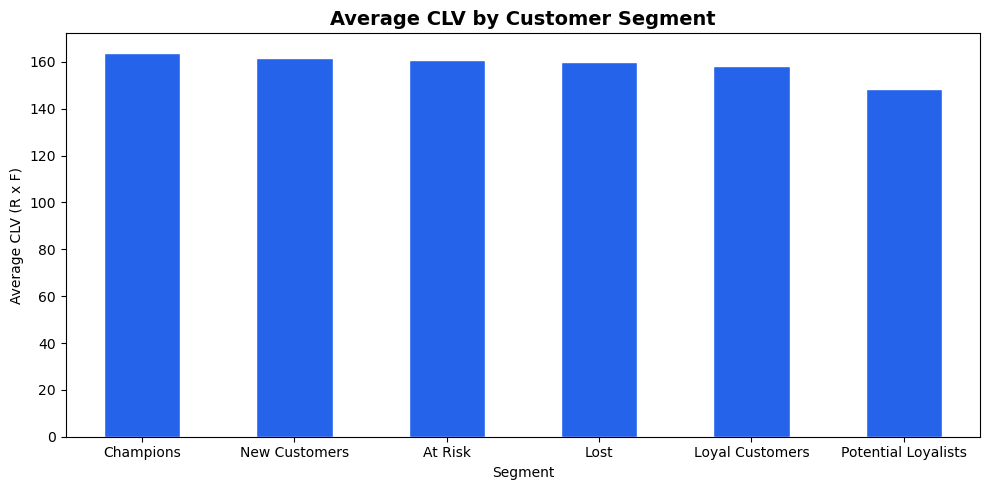

Saved chart to: /Users/divyanshaggarwal/Desktop/Intelligent-Customer-Analytics-Suite/05_Analytics/03_Visualizations/08_clv_segments.png
Champions CLV is dramatically higher — worth protecting at any retention cost.


In [5]:
plt.figure(figsize=(10, 5))
clv_by_segment.plot(kind='bar', color='#2563EB', edgecolor='white')
plt.title('Average CLV by Customer Segment', fontsize=14, fontweight='bold')
plt.xlabel('Segment')
plt.ylabel('Average CLV (R x F)')
plt.xticks(rotation=0)
plt.tight_layout()

save_dir = os.path.join(project_root, '05_Analytics', '03_Visualizations')
os.makedirs(save_dir, exist_ok=True)
save_path = os.path.join(save_dir, '08_clv_segments.png')
plt.savefig(save_path, dpi=150)
plt.show()

print("Saved chart to:", save_path)
print("Champions CLV is dramatically higher — worth protecting at any retention cost.")

## 💡 CLV Key Takeaways

- **Champions have dramatically higher CLV** than any other segment
- Lost customers have near-zero CLV — minimal resources should go toward win-back
- Clear upsell opportunity between Loyal Customers and Champions
- Investing in Champion retention has a far better ROI than acquiring new customers

---